# 01 · Split conformal prediction with no distribution shift (base case)

This first experiment establishes how ordinary split conformal prediction behaves when training, calibration and test observations are iid from the same joint distribution. Will later on consider other cases when the distribution shifts. 

$$X\sim N(0,1),\quad \varepsilon\sim N(0,1),\quad X\perp\varepsilon,\qquad
Y=2X+(0.5+0.5|X|)\varepsilon.$$

Write $\sigma(x)=0.5+0.5|x|$. Then $E[Y\mid X=x]=2x$ and $\mathrm{Var}(Y\mid X=x)=\sigma(x)^2$. The mean is linear but the noise is heteroscedastic: outcomes are more variable at large $|X|$. This variation with X is not distribution shift: the same conditional law and the same distribution of X apply to every split. Marginal Y is not assumed normal. This distribution was picked on purpose since we will implement the covariate shift next. 

**Research question:** does a finite-sample corrected 90% split CP procedure achieve approximately 90% marginal coverage across repeated experiments, and what does that conceal about coverage across X?

## 1. Design, assumptions and interpretation of the guarantee

| Sample | Default size | Permitted use |
|---|---:|---|
| Training | 500 | Fit an intercept and slope by ordinary least squares |
| Calibration | 500 | Choose the absolute-residual threshold |
| Test | 10,000 | Evaluate the already fixed intervals |
| Monte Carlo | 500 fresh experiments; 2,000 test points each | Estimate average coverage and width, including calibration variability |

For $\alpha=0.1$, calibration scores are $s_i=|y_i-\hat f(x_i)|$. Set
$$k=\lceil(n_{cal}+1)(1-\alpha)\rceil=451,\qquad
\hat q=s_{(k)},\qquad C(x)=[\hat f(x)-\hat q,\hat f(x)+\hat q].$$
The threshold is an order statistic without interpolation. If $k>n_{cal}$, the valid convention is $\hat q=+\infty$. Each interval predicts an individual future response, not the mean response.

Calibration and future observations are exchangeable conditional on the independently fitted model. The resulting marginal coverage is at least 90%, averaging over calibration data and a new observation; this is not a promise for each realised calibration set or each X. With continuous scores here, the rank argument gives $k/(n_{cal}+1)=451/501\approx90.02\%$. Heteroscedasticity does not invalidate this argument. Normality and a correct linear mean are simulation choices, not requirements of split CP validity. No model or threshold is selected using test outcomes.

In [1]:
import sys
import platform
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from IPython.display import display, Markdown

SEED = 42
MC_SEED = 2026
ALPHA = 0.10
N_TRAIN, N_CAL, N_TEST = 500, 500, 10_000
N_REPEATS, N_TEST_REPEAT = 500, 2_000
assert 0 < ALPHA < 1
assert N_TRAIN >= 2 and N_CAL >= 1 and N_TEST >= 1
assert N_REPEATS >= 2 and N_TEST_REPEAT >= 1
plt.rcParams.update({'font.size': 10, 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False})
BLUE, RED, GREEN = '#3569A8', '#C33C54', '#20836E'

def noise_sd(x):
    return 0.5 + 0.5 * np.abs(np.asarray(x))

def generate_data(n, rng):
    """Same law for every split. X and epsilon are independently sampled."""
    x = rng.normal(0.0, 1.0, size=n)
    epsilon = rng.normal(0.0, 1.0, size=n)
    return x, 2.0 * x + noise_sd(x) * epsilon

def fit_line(x, y):
    design = np.column_stack([np.ones(len(x)), x])
    return np.linalg.lstsq(design, y, rcond=None)[0]

def predict_line(beta, x):
    return beta[0] + beta[1] * np.asarray(x)

def conformal_threshold(scores, alpha):
    scores = np.asarray(scores, dtype=float)
    if not 0 < alpha < 1 or scores.ndim != 1 or scores.size == 0:
        raise ValueError('Use 0 < alpha < 1 and a nonempty score vector.')
    if not np.all(np.isfinite(scores)) or np.any(scores < 0):
        raise ValueError('Absolute-residual scores must be finite and nonnegative.')
    k = int(np.ceil((scores.size + 1) * (1 - alpha)))
    q = np.inf if k > scores.size else np.sort(scores)[k - 1]
    return float(q), k

def wilson_interval(successes, n, level=0.95):
    if n == 0:
        return np.nan, np.nan
    z = norm.ppf(0.5 + level / 2)
    p = successes / n
    denom = 1 + z*z/n
    center = (p + z*z/(2*n)) / denom
    half = z * np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / denom
    return center - half, center + half

def draw_splits(seed, n_train, n_cal, n_test):
    # Child streams separate sample roles; test size cannot change the fitted model.
    children = seed.spawn(3)
    return [generate_data(n, np.random.default_rng(s))
            for n, s in zip((n_train, n_cal, n_test), children)]

(x_train, y_train), (x_cal, y_cal), (x_test, y_test) = draw_splits(
    np.random.SeedSequence(SEED), N_TRAIN, N_CAL, N_TEST)
beta = fit_line(x_train, y_train)
print(f'Seed = {SEED}; Monte Carlo seed = {MC_SEED}')
print(f'Train / calibration / test: {N_TRAIN:,} / {N_CAL:,} / {N_TEST:,}')
print(f'Fitted mean: {beta[0]:.4f} + {beta[1]:.4f} x; true mean: 2 x')
print('Python:', platform.python_version())
display(pd.Series({name: version(name) for name in
                   ['numpy', 'pandas', 'scipy', 'matplotlib', 'ipython']},
                  name='Executed package version').to_frame())

Seed = 42; Monte Carlo seed = 2026
Train / calibration / test: 500 / 500 / 10,000
Fitted mean: -0.0163 + 2.0578 x; true mean: 2 x
Python: 3.13.9


,Executed package version
numpy,2.3.5
pandas,2.3.3
scipy,1.16.3
matplotlib,3.10.6
ipython,9.7.0


## 2. Initial Data Visualisation

The first panel uses training observations only. The shaded envelope is the known-law central 90% conditional interval, $2x\pm z_{0.95}\sigma(x)$, included to explain the simulation. It is not an estimated confidence band and is not used for calibration. The second panel plots noise around the true mean; its spread increases with $|X|$. OLS estimates the correct mean form, while its residual spread is not constant.

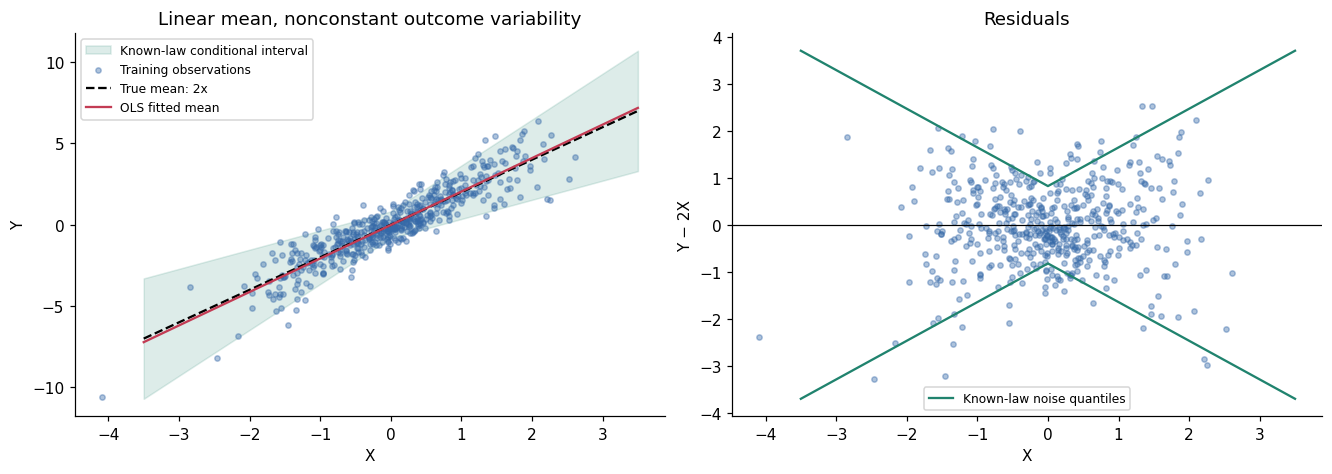

In [2]:
x_grid = np.linspace(-3.5, 3.5, 401)
oracle_z = norm.ppf(1 - ALPHA/2)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
axes[0].fill_between(x_grid, 2*x_grid-oracle_z*noise_sd(x_grid),
                     2*x_grid+oracle_z*noise_sd(x_grid),
                     color=GREEN, alpha=0.15, label='Known-law conditional interval')
axes[0].scatter(x_train, y_train, s=12, alpha=0.4, color=BLUE, label='Training observations')
axes[0].plot(x_grid, 2*x_grid, 'k--', label='True mean: 2x')
axes[0].plot(x_grid, predict_line(beta, x_grid), color=RED, label='OLS fitted mean')
axes[0].set(xlabel='X', ylabel='Y', title='Linear mean, nonconstant outcome variability')
axes[0].legend(fontsize=8)
axes[1].scatter(x_train, y_train-2*x_train, s=12, alpha=0.4, color=BLUE)
axes[1].plot(x_grid, oracle_z*noise_sd(x_grid), color=GREEN, label='Known-law noise quantiles')
axes[1].plot(x_grid, -oracle_z*noise_sd(x_grid), color=GREEN)
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set(xlabel='X', ylabel='Y − 2X', title='Residuals')
axes[1].legend(fontsize=8)
plt.show()

Evident from the residual plot, the magnitude of the residual increases as |X| increases, indicating heteroscedasticity. 

## 3. Calibrate once, then evaluate on untouched test data

A single absolute-residual threshold gives the same width $2\hat q$ at every X. The histogram and empirical CDF show exactly where calibration selects this threshold. Calibration coverage is not an independent assessment of performance because these scores choose the interval.

Corrected rank: k = 451 of 500; half-width q_hat = 1.54061
Calibration fraction at or below threshold: 90.200%


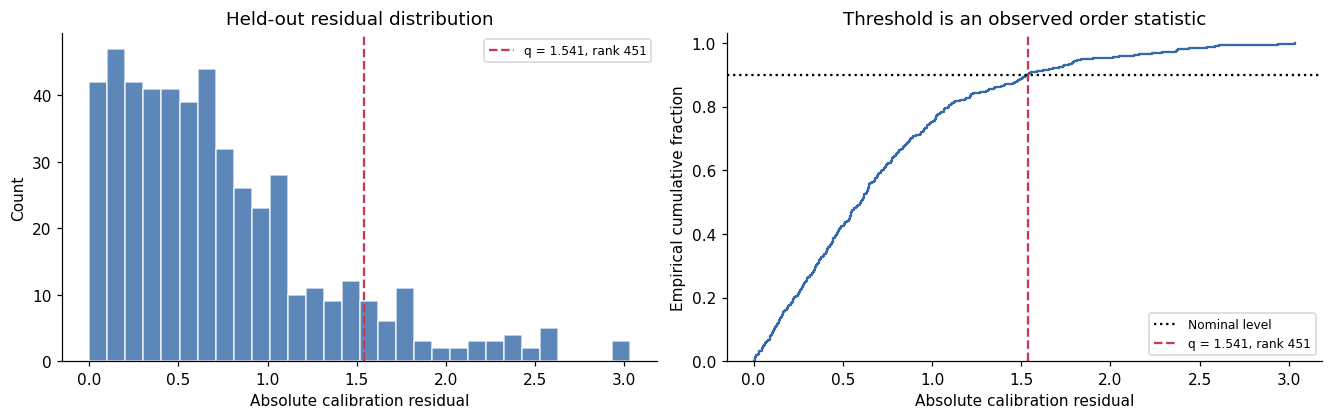

,Method,Test coverage,Mean width,Misses
0,Absolute-residual split CP,0.8998,3.0812,1002
1,Known-law conditional oracle,0.9014,2.9449,986


This split: 8,998/10,000 outcomes are covered (89.98%), with constant width 3.081. The 95% Wilson interval for test-sampling uncertainty is [89.38%, 90.55%]. It holds the fitted and calibrated interval fixed; it does not include uncertainty from a new training or calibration sample. The oracle changes width with X and has 90% coverage at each X under the known law. It has extra information unavailable to CP; its width is a descriptive benchmark, not a claimed optimum for all procedures with only marginal coverage.

In [3]:
cal_scores = np.abs(y_cal - predict_line(beta, x_cal))
q_hat, k = conformal_threshold(cal_scores, ALPHA)
y_pred = predict_line(beta, x_test)
lower, upper = y_pred - q_hat, y_pred + q_hat
covered = (lower <= y_test) & (y_test <= upper)
coverage, width = covered.mean(), 2*q_hat
test_low, test_high = wilson_interval(int(covered.sum()), N_TEST)
print(f'Corrected rank: k = {k} of {N_CAL}; half-width q_hat = {q_hat:.5f}')
print(f'Calibration fraction at or below threshold: {np.mean(cal_scores <= q_hat):.3%}')
fig, axes = plt.subplots(1, 2, figsize=(12, 3.7), constrained_layout=True)
axes[0].hist(cal_scores, bins=30, color=BLUE, alpha=0.8, edgecolor='white')
axes[0].set(xlabel='Absolute calibration residual', ylabel='Count', title='Held-out residual distribution')
sorted_scores = np.sort(cal_scores)
axes[1].step(sorted_scores, np.arange(1, N_CAL+1)/N_CAL, where='post', color=BLUE)
axes[1].axhline(1-ALPHA, color='black', linestyle=':', label='Nominal level')
axes[1].set(xlabel='Absolute calibration residual', ylabel='Empirical cumulative fraction',
            title='Threshold is an observed order statistic', ylim=(0, 1.03))
for ax in axes:
    ax.axvline(q_hat, color=RED, linestyle='--', label=f'q = {q_hat:.3f}, rank {k}')
    ax.legend(fontsize=8)
plt.show()

# The oracle uses the KNOWN conditional distribution, only as an explanatory benchmark.
oracle_half = oracle_z * noise_sd(x_test)
oracle_covered = np.abs(y_test-2*x_test) <= oracle_half
summary = pd.DataFrame({
    'Method': ['Absolute-residual split CP', 'Known-law conditional oracle'],
    'Test coverage': [coverage, oracle_covered.mean()],
    'Mean width': [width, (2*oracle_half).mean()],
    'Misses': [(~covered).sum(), (~oracle_covered).sum()]})
display(summary.round(4))
display(Markdown(
    f'This split: {covered.sum():,}/{N_TEST:,} outcomes are covered '
    f'({coverage:.2%}), with constant width {width:.3f}. '
    f'The 95% Wilson interval for test-sampling uncertainty is '
    f'[{test_low:.2%}, {test_high:.2%}]. It holds the fitted and calibrated interval fixed; '
    'it does not include uncertainty from a new training or calibration sample. '
    'The oracle changes width with X and has 90% coverage at each X under the known law. '
    'It has extra information unavailable to CP; its width is a descriptive benchmark, '
    'not a claimed optimum for all procedures with only marginal coverage.'))

## 4. Prediction intervals versus realised outcomes

The first 60 test observations are selected by index, without looking at outcomes, and sorted by X only for display. Blue dots are covered and red crosses are missed. The second panel compares the constant-width CP band with the changing width of the known-law interval. A global threshold can be generous near X = 0 and too narrow in the tails.

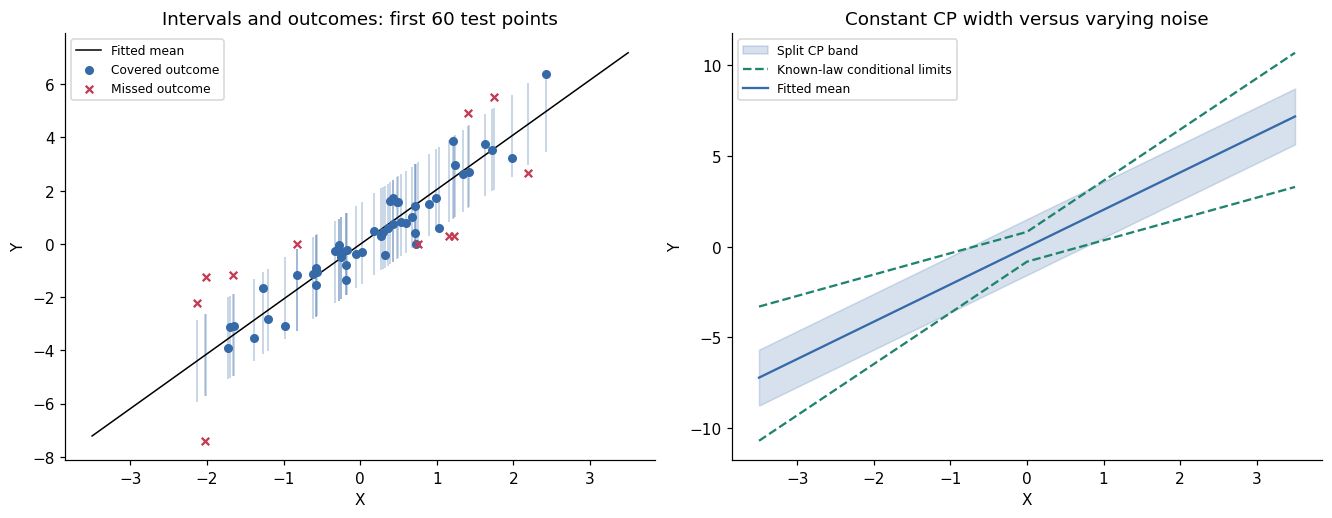

,X,Observed Y,Predicted Y,Lower,Upper,Covered
0,-1.649,-3.085,-3.410,-4.951,-1.870,True
1,1.406,4.905,2.877,1.336,4.418,False
2,0.723,-0.015,1.472,-0.068,3.013,True
3,-0.829,-1.162,-1.722,-3.263,-0.182,True
4,0.484,1.564,0.979,-0.561,2.520,True
5,-1.198,-2.805,-2.481,-4.021,-0.940,True
6,-0.281,-0.038,-0.595,-2.136,0.945,True
7,-0.826,-0.018,-1.717,-3.257,-0.176,False
8,-0.328,-0.268,-0.692,-2.233,0.849,True
9,0.185,0.469,0.364,-1.177,1.905,True


In [4]:
show = np.arange(min(60, N_TEST))
show = show[np.argsort(x_test[show])]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True)
ax = axes[0]
ax.vlines(x_test[show], lower[show], upper[show], color=BLUE, alpha=0.35, linewidth=1)
ax.plot(x_grid, predict_line(beta, x_grid), color='black', linewidth=1, label='Fitted mean')
for mask, color, marker, label in [(covered[show], BLUE, 'o', 'Covered outcome'),
                                  (~covered[show], RED, 'x', 'Missed outcome')]:
    idx = show[mask]
    ax.scatter(x_test[idx], y_test[idx], color=color, marker=marker, s=24, label=label, zorder=3)
ax.set(xlabel='X', ylabel='Y', title=f'Intervals and outcomes: first {len(show)} test points')
ax.legend(fontsize=8)
ax = axes[1]
f_grid = predict_line(beta, x_grid)
ax.fill_between(x_grid, f_grid-q_hat, f_grid+q_hat, color=BLUE, alpha=0.2, label='Split CP band')
ax.plot(x_grid, 2*x_grid-oracle_z*noise_sd(x_grid), '--', color=GREEN, label='Known-law conditional limits')
ax.plot(x_grid, 2*x_grid+oracle_z*noise_sd(x_grid), '--', color=GREEN)
ax.plot(x_grid, f_grid, color=BLUE, label='Fitted mean')
ax.set(xlabel='X', ylabel='Y', title='Constant CP width versus varying noise')
ax.legend(fontsize=8)
plt.show()
display(pd.DataFrame({'X': x_test[:10], 'Observed Y': y_test[:10],
                      'Predicted Y': y_pred[:10], 'Lower': lower[:10],
                      'Upper': upper[:10], 'Covered': covered[:10]}).round(3))

## 5. Overall coverage can hide uneven coverage across X

These X bins are fixed before inspecting outcomes. Their Wilson intervals describe test-sampling uncertainty within this one split, are not simultaneous, and do not include calibration variability. Binned coverage is not pointwise conditional coverage.

Because the generating law is known, the exact coverage at a fixed x for this fitted and calibrated interval is
$$p(x)=\Phi\!\left(\frac{\hat f(x)+\hat q-2x}{\sigma(x)}\right)-
\Phi\!\left(\frac{\hat f(x)-\hat q-2x}{\sigma(x)}\right).$$
This diagnostic uses no estimated noise model and never changes the CP intervals. The unconditional residual is a mixture here; the old constant-noise normal-residual formula is inapplicable.

,X range,Test n,Coverage,95% low,95% high
0,X ≤ −1.5,672,0.7009,0.6652,0.7343
1,−1.5 < X ≤ −0.5,2438,0.8905,0.8775,0.9023
2,−0.5 < X ≤ 0.5,3833,0.9833,0.9787,0.9869
3,0.5 < X ≤ 1.5,2411,0.8847,0.8713,0.8968
4,X > 1.5,646,0.7028,0.6664,0.7367


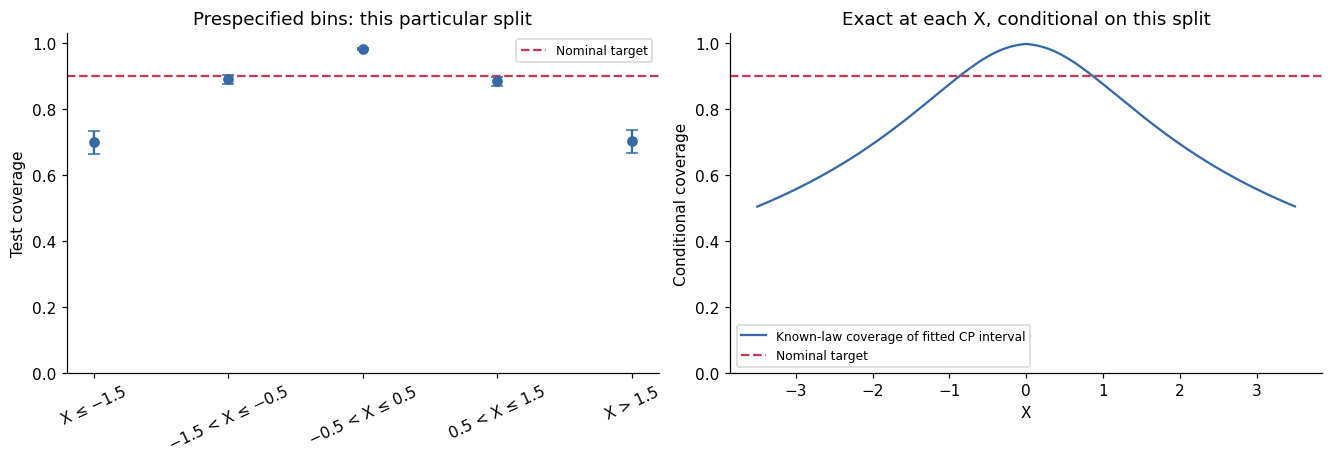

In [5]:
edges = np.array([-np.inf, -1.5, -0.5, 0.5, 1.5, np.inf])
labels = ['X ≤ −1.5', '−1.5 < X ≤ −0.5', '−0.5 < X ≤ 0.5', '0.5 < X ≤ 1.5', 'X > 1.5']
rows = []
for j, label in enumerate(labels):
    mask = (x_test > edges[j]) & (x_test <= edges[j+1])
    n = int(mask.sum())
    successes = int(covered[mask].sum())
    lo, hi = wilson_interval(successes, n)
    rows.append([label, n, successes/n if n else np.nan, lo, hi])
by_x = pd.DataFrame(rows, columns=['X range', 'Test n', 'Coverage', '95% low', '95% high'])
display(by_x.round(4))
p_x = (norm.cdf((f_grid+q_hat-2*x_grid)/noise_sd(x_grid))
       - norm.cdf((f_grid-q_hat-2*x_grid)/noise_sd(x_grid)))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.1), constrained_layout=True)
axes[0].errorbar(np.arange(5), by_x['Coverage'],
                yerr=[by_x['Coverage']-by_x['95% low'], by_x['95% high']-by_x['Coverage']],
                fmt='o', color=BLUE, capsize=4)
axes[0].set(xticks=np.arange(5), xticklabels=labels, ylabel='Test coverage',
            title='Prespecified bins: this particular split', ylim=(0, 1.03))
axes[0].tick_params(axis='x', labelrotation=25)
axes[1].plot(x_grid, p_x, color=BLUE, label='Known-law coverage of fitted CP interval')
axes[1].set(xlabel='X', ylabel='Conditional coverage', title='Exact at each X, conditional on this split', ylim=(0, 1.03))
for ax in axes:
    ax.axhline(1-ALPHA, color=RED, linestyle='--', label='Nominal target')
    ax.legend(fontsize=8)
plt.show()

Coverage is higher near the low-noise centre and lower at large |X|. A correct linear mean does not remove this pattern because noise variance still changes. Marginal validity allows such unevenness: it averages over the baseline distribution of X. Later on we will shift the distribution of X to area where there is less coverage to demonstrate the effect of covariate shifts. 

## 6. Repeating the experiment (including training and calibration)

Each repetition draws three fresh independent samples, refits OLS, recalibrates and evaluates on 2,000 new test observations. Reusing one calibration set would answer a different question. We report the mean and standard deviation of the per-repetition coverage and width, plus Monte Carlo standard errors (MCSE = between-repetition SD / $\sqrt{B}$). Treat repetitions as independent units: pooling all test outcomes as independent would ignore their shared calibration threshold within each run.

The approximate 95% Monte Carlo intervals measure uncertainty in simulation averages, not prediction intervals. An individual experiment need not achieve 90%. Seeds and settings are fixed in advance and are not adjusted to obtain a favourable result.

,Mean,Between-run SD,MCSE,95% MC low,95% MC high
Test coverage,0.900212,0.014900,0.000666,0.898906,0.901518
Width,3.081845,0.156296,0.006990,3.068145,3.095545


,Test coverage,Width
Across-run quantile,,
0.05,0.8735,2.8318
0.50,0.9010,3.0724
0.95,0.9220,3.3419


Continuous-score theoretical marginal coverage: 451/501 = 90.01996%
Fraction of runs with test coverage below nominal: 45.8%


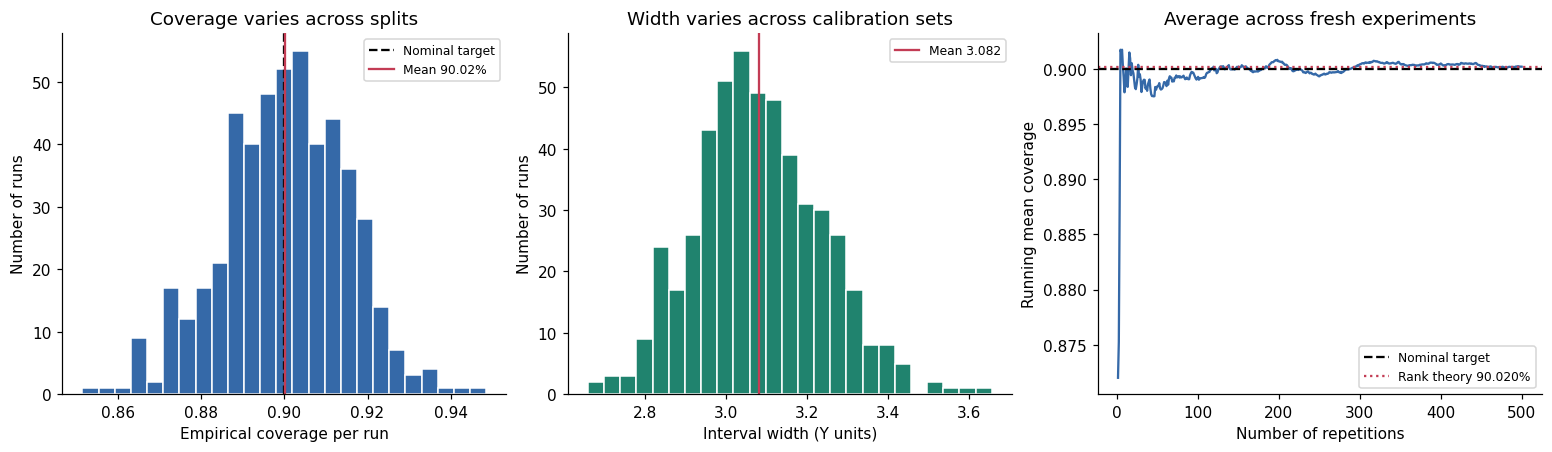

Repeated-experiment result: mean coverage is 90.02% (MCSE 0.067 percentage points; approximate 95% MC interval [89.89%, 90.15%]). The rank-theory value is 90.02%. Mean interval width is 3.082 Y units (MCSE 0.0070). Width is constant within a run but varies between runs because calibration data change. Simulation estimates, rather than proves, the coverage property.

In [6]:
records = []
for rep_seed in np.random.SeedSequence(MC_SEED).spawn(N_REPEATS):
    (xt, yt), (xc, yc), (xe, ye) = draw_splits(rep_seed, N_TRAIN, N_CAL, N_TEST_REPEAT)
    b = fit_line(xt, yt)
    q, _ = conformal_threshold(np.abs(yc-predict_line(b, xc)), ALPHA)
    empirical = np.mean(np.abs(ye-predict_line(b, xe)) <= q)
    records.append((empirical, 2*q))
repeats = pd.DataFrame(records, columns=['Test coverage', 'Width'])
mc_mean, mean_width = repeats.mean()
mc_se, width_se = repeats.std(ddof=1)/np.sqrt(N_REPEATS)
theory_coverage = min(k/(N_CAL+1), 1.0)
mc_summary = pd.DataFrame({'Mean': repeats.mean(), 'Between-run SD': repeats.std(ddof=1),
                           'MCSE': repeats.std(ddof=1)/np.sqrt(N_REPEATS)})
mc_summary['95% MC low'] = mc_summary['Mean']-1.96*mc_summary['MCSE']
mc_summary['95% MC high'] = mc_summary['Mean']+1.96*mc_summary['MCSE']
display(mc_summary.round(6))
display(repeats.quantile([0.05, 0.5, 0.95]).rename_axis('Across-run quantile').round(4))
print(f'Continuous-score theoretical marginal coverage: {k}/{N_CAL+1} = {theory_coverage:.5%}')
print(f'Fraction of runs with test coverage below nominal: {(repeats["Test coverage"] < 1-ALPHA).mean():.1%}')

fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
axes[0].hist(repeats['Test coverage'], bins=25, color=BLUE, edgecolor='white')
axes[0].axvline(1-ALPHA, color='black', linestyle='--', label='Nominal target')
axes[0].axvline(mc_mean, color=RED, label=f'Mean {mc_mean:.2%}')
axes[0].set(xlabel='Empirical coverage per run', ylabel='Number of runs', title='Coverage varies across splits')
axes[0].legend(fontsize=8)
axes[1].hist(repeats['Width'], bins=25, color=GREEN, edgecolor='white')
axes[1].axvline(mean_width, color=RED, label=f'Mean {mean_width:.3f}')
axes[1].set(xlabel='Interval width (Y units)', ylabel='Number of runs', title='Width varies across calibration sets')
axes[1].legend(fontsize=8)
axes[2].plot(np.arange(1, N_REPEATS+1), repeats['Test coverage'].expanding().mean(), color=BLUE)
axes[2].axhline(1-ALPHA, color='black', linestyle='--', label='Nominal target')
axes[2].axhline(theory_coverage, color=RED, linestyle=':', label=f'Rank theory {theory_coverage:.3%}')
axes[2].set(xlabel='Number of repetitions', ylabel='Running mean coverage', title='Average across fresh experiments')
axes[2].legend(fontsize=8)
plt.show()
display(Markdown(
    f'Repeated-experiment result: mean coverage is {mc_mean:.2%} '
    f'(MCSE {100*mc_se:.3f} percentage points; approximate 95% MC interval '
    f'[{mc_mean-1.96*mc_se:.2%}, {mc_mean+1.96*mc_se:.2%}]). '
    f'The rank-theory value is {theory_coverage:.2%}. Mean interval width is '
    f'{mean_width:.3f} Y units (MCSE {width_se:.4f}). '
    'Width is constant within a run but varies between runs because calibration data change. '
    'Simulation estimates, rather than proves, the coverage property.'))

## 7. Implementation checks and reproducibility

Checks target the data-generating law, finite-sample rank, infinite-threshold edge case, interval endpoints, OLS fitting and exact reproduction of the seeded data. They do **not** demand that one split reach 90%. To reproduce, use **Kernel → Restart Kernel and Run All Cells**. Keep the printed package versions for exact environment reproduction; tiny numerical differences across platforms are possible. No external data are needed.

Change the configuration in Section 1 and rerun all cells for a sensitivity analysis. The live numerical interpretations update automatically. The default calibration sample is large enough for a finite threshold; very small calibration samples at high requested coverage can require an infinite interval and are not suitable for the finite-width plots.

In [7]:
assert conformal_threshold([4., 1., 3., 2.], 0.4) == (3., 3)
assert conformal_threshold([1., 2., 3.], 0.5) == (2., 2)
assert np.isinf(conformal_threshold([1., 2., 3.], 0.1)[0])
assert conformal_threshold([1., 1., 1.], 0.5) == (1., 2)
assert k == int(np.ceil((N_CAL+1)*(1-ALPHA)))
assert q_hat == (np.sort(cal_scores)[k-1] if k <= N_CAL else np.inf)
assert np.all(lower <= upper)
assert np.allclose(upper-lower, width)
assert np.array_equal(covered, np.abs(y_test-y_pred) <= q_hat)
assert np.allclose(fit_line(np.array([-1., 0., 1.]), np.array([-2., 0., 2.])), [0., 2.])
# Reconstruct X and epsilon directly: detects accidental constant-noise generation.
check_rng = np.random.default_rng(123)
check_x = check_rng.normal(size=20)
check_epsilon = check_rng.normal(size=20)
check_generated = generate_data(20, np.random.default_rng(123))
assert np.array_equal(check_x, check_generated[0])
assert np.array_equal(check_generated[1], 2*check_x+(0.5+0.5*np.abs(check_x))*check_epsilon)
reproduced = draw_splits(np.random.SeedSequence(SEED), N_TRAIN, N_CAL, N_TEST)
for original, again in zip(((x_train, y_train), (x_cal, y_cal), (x_test, y_test)), reproduced):
    assert all(np.array_equal(a, b) for a, b in zip(original, again))
assert repeats.shape == (N_REPEATS, 2)
assert repeats['Test coverage'].between(0, 1).all()
print('All implementation and seeded-reproduction checks passed.')

All implementation and seeded-reproduction checks passed.


## 8. Continue to the next part: introducing covariate shifts

The baseline separates three issues. First, the fitted line estimates the correct conditional mean. Second, held-out calibration converts prediction errors into a single interval width. Third, the repeated experiment assesses the procedure's marginal coverage over new training, calibration and test samples. One split and the repeated average answer different questions; neither should be selected or reported only when it looks favourable.

The experiment can support a claim of agreement with the iid marginal-coverage benchmark, subject to the reported Monte Carlo uncertainty. It cannot support a claim of 90% coverage for every X, every subgroup or every realised calibration set. The coverage-by-X diagnostic shows why: the interval width is fixed while the true conditional noise scale increases with $|X|$. Report interval width alongside coverage to describe informativeness.

The work from here on is (1) this iid no-shift baseline, (2) a separate simulated covariate-shift study, (3) a comparison with weighted CP, and potentially (4) an application to the Airfoil data. For a clean later covariate-shift comparison, retain $Y\mid X=x\sim N(2x,(0.5+0.5|x|)^2)$ and change only the distribution of X. Increasing the prevalence of large $|X|$ would place more test observations in high-noise regions; the amount of coverage change must be measured in that later experiment. No shifted data, importance weights or weighted-CP results are included in this notebook.

Making sure: include the generating law, separate sample sizes, nominal level, exact order-statistic rule, seeds, number of independent repetitions, MCSE, coverage and width summaries, package versions, and the distinction between marginal and conditional coverage. This will be the baseline specification before designing subsequent experiments.